# 3.01. Мета-анализ A/B-тестов

**План занятия**

1. Что такое мета-анализ, его сильные стороны и ограничения.
2. Модели фиксированных и случайных эффектов.
3. Методы для бинарных и непрерывных исходов.
4. Мета-регрессия.
5. Синтез значимостей: методы Фишера, Стоуффера и HMP.
6. Лесной и воронкообразный графики, публикационное смещение.
7. Пример: галоперидол против плацебо.

### Библиотеки

Для сверки результатов используется `PythonMeta`. В Colab его можно поставить командой `!pip install -q PythonMeta`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PythonMeta as PMA
import scipy.stats as st
import seaborn as sns
import statsmodels.api as sm
from ipywidgets import FloatSlider, interact

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
rng = np.random.default_rng(42)


def fixed_effect(y, v):
    """Считает оценку с обратными дисперсиями и статистику Q."""
    w = 1 / v
    mean = np.sum(w * y) / np.sum(w)
    return mean, np.sqrt(1 / np.sum(w)), np.sum(w * (y - mean) ** 2)


def dersimonian_laird(y, v):
    """Оценивает межисследовательскую дисперсию методом моментов."""
    w = 1 / v
    _, _, q = fixed_effect(y, v)
    c = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    return max(0.0, (q - (len(y) - 1)) / c)


def random_effects(y, v):
    """Возвращает оценку случайных эффектов, её SE и SE с поправкой Хартунга — Кнаппа."""
    tau2 = dersimonian_laird(y, v)
    w = 1 / (v + tau2)
    mean = np.sum(w * y) / np.sum(w)
    se = np.sqrt(1 / np.sum(w))
    hk = np.sqrt(np.sum(w * (y - mean) ** 2) / (len(y) - 1) / np.sum(w))
    return mean, se, hk, tau2

## Сущность мета-анализа

**Мета-анализ** представляет собой **статистический анализ, объединяющий и/или интегрирующий количественные данные из множества независимых исследований, посвященных одному и тому же исследовательскому вопросу**. Это статистический (или количественный) анализ, который отличается от традиционного нарративного обзора, где заключения делаются на основе качественной оценки исследований. По сути, мета-анализ — это «анализ анализов» (как определил Джин Гласс в 1976 году), который проводит операцию слияния данных (data fusion), давая оценку оценкам. Анализ обычно проводится на уровне исследования, то есть является «исследованием исследований».

**Фундаментальная цель мета-анализа** заключается в следующем:
*   **Вычисление объединенного размера эффекта** (combined effect size) по всем включенным исследованиям. Это позволяет получить усредненную или комбинированную оценку эффекта по всем работам.
*   **Повышение статистической мощности** (statistical power) и способности измерять слабые сигналы. Индивидуальные исследования могут обладать низкой мощностью для достижения статистической значимости при небольшом, но клинически важном эффекте. Объединение множества исследований увеличивает размер выборки, позволяя выявить такие эффекты.
*   **Разрешение неопределенностей или несоответствий** между результатами отдельных исследований. Мета-анализ позволяет выявлять факторы, объясняющие различия в результатах исследований, часто посредством стратифицированного или регрессионного анализа, что может генерировать новые гипотезы для будущих исследований.
*   **Интеграция и обобщение существующих знаний**, что играет ключевую роль в обосновании предложений по грантам, формировании рекомендаций по лечению и влиянии на политику здравоохранения. Он служит агрегатором для серии результатов тестов, повышая уровень доказательности и позволяя более уверенно внедрять статистически значимые инициативы.

**Сильные стороны и ограничения**

Мета-анализ, несмотря на свою методологическую строгость, не лишен недостатков и требует критического подхода к интерпретации результатов.

* **Сильные стороны мета-анализа**

  1.  **Повышенная объективность и воспроизводимость:**
    *   Мета-анализ привносит в процесс литературного обзора такую же **методологическую строгость**, которая требуется от экспериментальных исследований.
    *   В отличие от нарративных обзоров, выбор исследований в мета-анализе основан не на произволе автора, а на **публично разделяемых стандартах** и четко определенных критериях включения/исключения.
    *   Мета-анализ требует, чтобы все **субъективные решения**, принимаемые авторами (например, при кодировании модераторов), были **сделаны публичными**, что делает их открытыми для критики и повышает прозрачность. Это облегчает выявление некорректно проведенных мета-анализов по сравнению с нарративными обзорами, где специфическое содержание часто скрыто.

  2.  **Обобщение результатов и повышение статистической мощности:**
    *   Объединение данных из нескольких исследований **увеличивает совокупный размер выборки**, что приводит к более **высокой статистической мощности**, сужению доверительных интервалов (CI). Это позволяет выявлять эффекты, которые могли быть статистически незначимыми в отдельных небольших исследованиях.
    *   Мета-анализ эффективно объединяет все собранные данные, создавая эффект более масштабного и надежного эксперимента.
    *   Современный мета-анализ выходит за рамки простого объединения размеров эффектов, позволяя **тестировать изменчивость результатов** сверх ожидаемой из-за случайной выборки. Характеристики исследований (например, используемые инструменты измерения, популяции, дизайн) могут быть закодированы и использованы для снижения дисперсии оценки, что позволяет **статистически корректировать некоторые методологические недостатки**.
    *   Это смещает акцент с отдельных исследований на их совокупность, подчеркивая **практическую значимость размера эффекта**, а не только статистическую значимость.

  3.  **Возможность анализа подгрупп и модераторов:**
    *   Мета-анализ не игнорирует качественные различия между исследованиями, а **кодирует их как переменные-модераторы**, что позволяет эмпирически тестировать их влияние.
    *   Мета-регрессия играет **критически важную роль в учете эффектов ковариат**, особенно при наличии категориальных переменных, которые могут быть использованы для анализа подгрупп.
    *   Исследователи могут выявить факторы, объясняющие различия в результатах исследований, проводя стратифицированный анализ или мета-регрессию.

* **Опасения и ограничения мета-анализа**

  1.  **«Мусор на входе — мусор на выходе» (Garbage In, Garbage Out):**
    *   **Мета-анализ не может исправить недостатки дизайна или предвзятость (bias) в исходных исследованиях**. Если первичные исследования методологически некорректны, валидность мета-анализа будет поставлена под сомнение.
    *   Поэтому крайне важно включать только **методологически обоснованные исследования** (подход «синтез лучших доказательств»).
    *   Авторы мета-анализов должны кодировать характеристики качества исследований, чтобы оценить, влияет ли качество на размер эффекта. Если такая зависимость существует, низкокачественные исследования могут быть исключены или их влияние учтено.

  2.  **Гетерогенность (Heterogeneity):**
    *   **Гетерогенность** — это изменчивость истинных эффектов между исследованиями, обусловленная различиями в методологии, характеристиках выборки или других факторах.
    *   **Предположение однородности** (homogeneity), лежащее в основе моделей фиксированных эффектов (fixed effect models), заключается в том, что все исследования оценивают один и тот же основной параметр популяции. Однако это часто нереалистично, поскольку исследования подвержены различным источникам гетерогенности.
    *   При наличии гетерогенности **не существует единого размера эффекта для популяции** (δ), и каждое исследование оценивает свой собственный специфический эффект (δᵢ). В таких случаях комбинированная оценка может не отражать истинного значения для какой-либо конкретной популяции.
    *   **Чрезмерная межисследовательская изменчивость** может сделать комбинированную оценку бессмысленной, для чего были созданы методы выявления гетерогенности: **тест Кохрана Q**, **статистика I²** ...

  3.  **Предвзятость публикаций (Publication Bias), «Проблема запертого ящика» (File Drawer Problem):**
    *   **Предвзятость публикаций** возникает из-за тенденции публиковать исследования, демонстрирующие статистически значимые положительные результаты, в то время как исследования с отрицательными или незначимыми результатами остаются неопубликованными.
    *   Это приводит к **искаженным (преувеличенным) выводам** в мета-анализах, основанных только на опубликованных работах, и оценка эффекта завышается.
    *   **«Проблема запертого ящика»** (file drawer problem) описывает ситуацию, когда исследования с «неинтересными» результатами остаются «запертыми в ящиках» исследователей и не попадают в научную литературу.
    *   **Проблема заключается не только в журнальных практиках**, но и в **сомнительных исследовательских практиках** самих авторов, которые могут подгонять статистические модели до достижения значимости.

  4.  **«Эффект яблока и апельсина» (Combining Apples and Oranges):**
    *   Это распространенная критика, утверждающая, что мета-анализ **объединяет несравнимые исследования**. Если методологии исследований слишком сильно различаются, выводы могут быть ошибочными.
    *   **Ответ:** Авторы мета-анализов должны четко определить **критерии включения и исключения** исследований, чтобы обеспечить их сравнимость и теоретическую однородность. Мета-анализ не игнорирует качественные различия, а кодирует их как модераторы, чтобы эмпирически проверить их влияние. Однако **слабые стандарты включения** действительно могут привести к вводящим в заблуждение выводам.


Таким образом, мета-анализ является мощным инструментом для синтеза научных доказательств, но его применение требует тщательного соблюдения методологии, критической оценки первичных исследований и внимательного учета потенциальных источников смещения и гетерогенности.

## Типы и методы мета-анализа

Базово есть несколько методов, зависящих от типа данных и целей анализа. Если мы хотим оценить размер эффекта, то применяются разные методы количественного синтеза. Если же мы хотим оценить валидность гипотез, то синтез значимостей. Здесь мы пройдёмся по базовым методам этих анализов, которые представлены на графе
 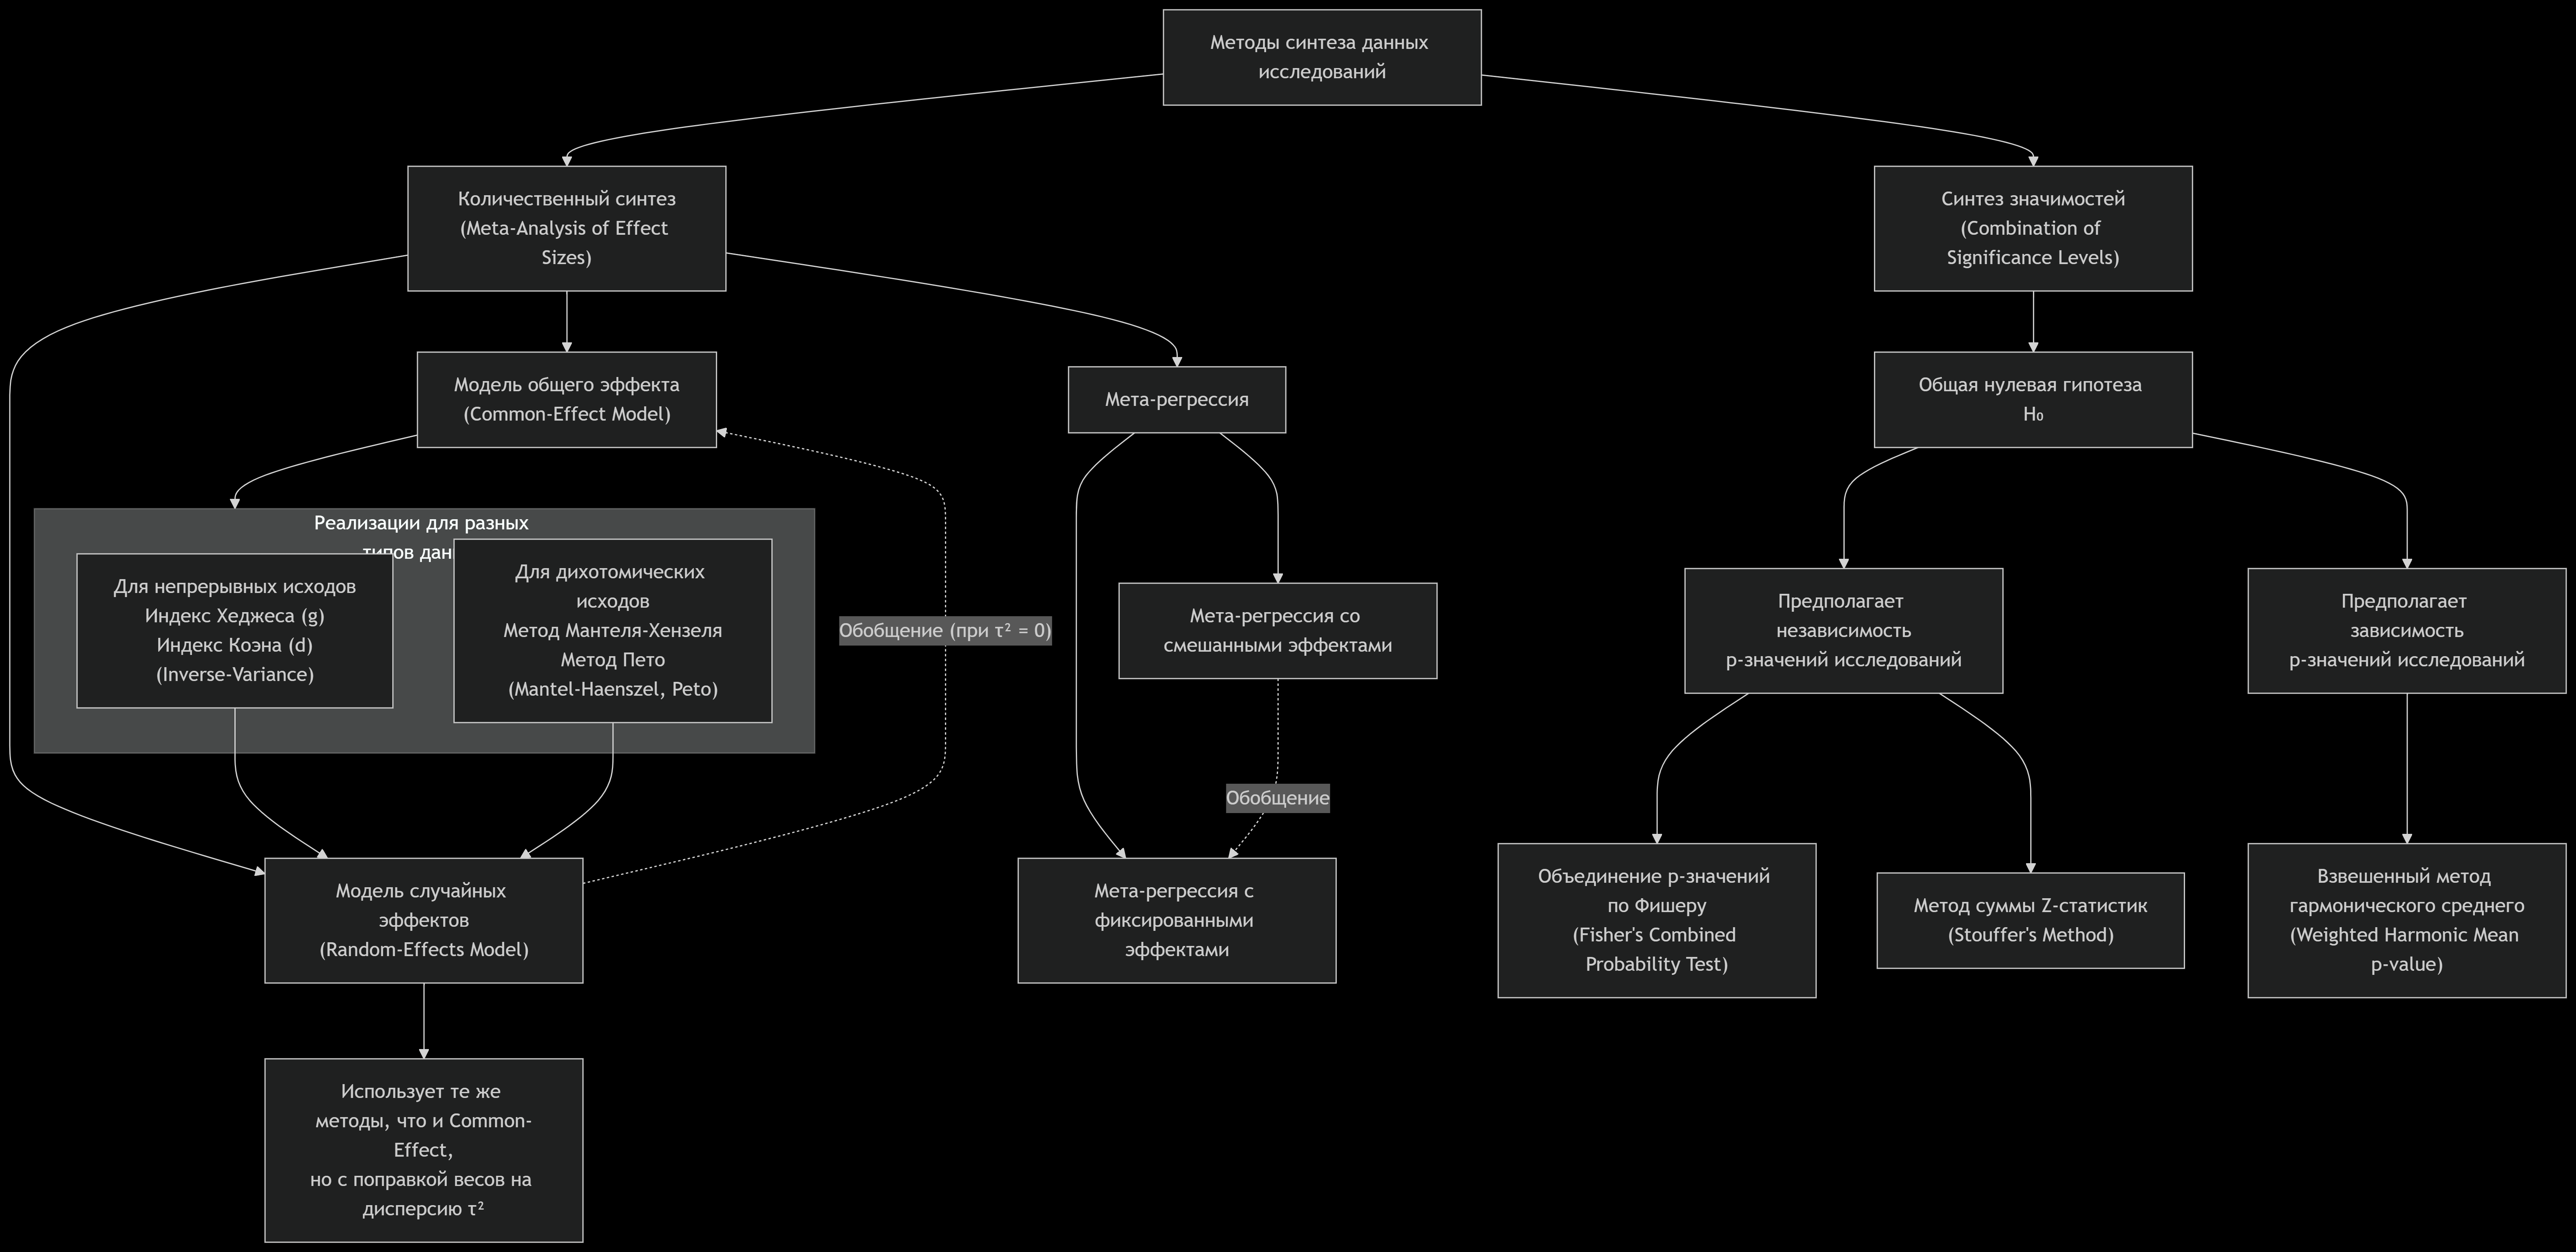

### Количественный синтез

####  Классический количественный синтез

##### Выбор модели

При проведении мета-анализа одним из фундаментальных решений является выбор между моделями **фиксированных эффектов (Fixed-Effect)** и **случайных эффектов (Random-Effects)**.


**Модель фиксированных эффектов (Fixed-Effect Model)**

Эта модель **предполагает, что все включенные исследования оценивают один и тот же основной истинный эффект ($δ$)**. Таким образом, наблюдаемые различия между оценками эффектов в разных исследованиях объясняются исключительно случайной ошибкой выборки. Это означает, что если бы каждое первичное исследование имело бесконечный размер выборки, оценка эффекта в нем точно совпадала бы с $δ$. Модель фиксированных эффектов **подходит, когда исследования считаются гомогенными**, то есть однородными по методам, популяциям и другим характеристикам.
  
В этой модели используется **Inverse-Variance Weighting**, где вес ($w_i$), присваиваемый каждому исследованию $i$, **обратно пропорционален дисперсии оценки эффекта этого исследования** ($d_i$). Это означает, что более точные исследования (с меньшей стандартной ошибкой и, следовательно, меньшей дисперсией) получают больший вес.

$$w_i = \frac{1}{\text{Var}(d_i)} = \frac{1}{\text{SE}(d_i)^2} \quad$$
  
Объединенная оценка эффекта ($\overline{T}$) рассчитывается как **взвешенное среднее оценок эффектов отдельных исследований**:

$$\overline{T} = \frac{\sum w_i T_i}{\sum w_i} \\
\text{где $T_i$ — это оценка размера эффекта для $i$-го исследования}
$$

Для проверки предположения о гомогенности используется **статистика Q-теста Кохрана**. Она измеряет общую вариабельность в наборе размеров эффектов и следует распределению хи-квадрат с $k-1$ степенями свободы, где $k$ — количество исследований. Большие значения $Q_T$ указывают на то, что наблюдаемые исследования, вероятно, происходят из нескольких популяций (т.е., присутствует гетерогенность).

$$Q_T = \sum w_i (T_i - \overline{T})^2 = \sum w_i (T_i)^2 - \frac{(\sum w_i T_i)^2}{\sum w_i} \quad$$


**Модель случайных эффектов (Random-Effects Model)**

В отличие от фиксированных эффектов, эта модель **предполагает, что каждое исследование оценивает свой собственный, уникальный популяционный размер эффекта ($δ_i$)**. Эти индивидуальные истинные эффекты ($δ_i$) **считаются случайной выборкой из более широкого распределения популяционных эффектов**, которое имеет среднее значение ($δ$) и дисперсию между исследованиями ($τ²$). Таким образом, модель случайных эффектов учитывает два источника вариабельности: внутриисследовательскую вариабельность (ошибка выборки) и межисследовательскую вариабельность (гетерогенность). Модель случайных эффектов является более распространенным выбором, поскольку на практике исследования редко бывают идеально идентичными, и гетерогенность часто присутствует.

Самый распространённый подход для оценки межисследовательской дисперсии $\tau^2$ — **метод ДерСимониана — Лэрда (DerSimonian-Laird)**, который основан на статистике $Q$-теста:

1. Сначала вычисляется **$Q$-статистика** (известная как $Q_T$) с использованием весов фиксированных эффектов $w_i = 1/\text{SE}(d_i)^2$:

$$Q = \sum_{i=1}^k w_i (d_i - \overline{d})^2$$

2.  Затем оценивается межисследовательская дисперсия $\tau^2$ с помощью следующей формулы:

$$\tau^2 = \frac{Q - (k-1)}{C} \\
\text{где $k$ — количество исследований, а $C$ — это коэффициент, вычисляемый как}
$$

$$C = \sum_{i=1}^k w_i - \frac{\sum_{i=1}^k w_i^2}{\sum_{i=1}^k w_i} \quad$$
  
  Если $Q < k-1$, то $\tau^2$ устанавливается равным 0, поскольку отрицательная дисперсия не имеет физического смысла.
  **Проблема** этого метода в том, что при небольшом числе исследований оценка $\tau^2$ очень неточна. Но обычный доверительный интервал считает $\tau^2$ известным, поэтому он слишком узок. Для этого есть поправка **Хартунга — Кнаппа**: дисперсия умножается на $q = \frac{1}{k-1}\sum w_i^*(d_i - \overline{d}^*)^2$, а вместо нормального распределения берётся $t_{k-1}$.

В модели случайных эффектов веса для каждого исследования ($w_i^*$) корректируются с учетом как внутриисследовательской дисперсии ($s_i^2$, которая равна $\text{SE}(d_i)^2$), так и оцененной межисследовательской дисперсии ($\tau^2$).

$$w_i^* = \frac{1}{s_i^2 + \tau^2} = \frac{1}{\text{SE}(d_i)^2 + \tau^2} \quad
\text{}
$$

Эти веса $w_i^*$ для модели случайных эффектов стремятся к более равномерному распределению весов между исследованиями по сравнению с весами фиксированных эффектов. Они уменьшают вес наиболее точных исследований и увеличивают вес менее точных.

Объединенная оценка эффекта в модели случайных эффектов ($\overline{d}^*$) также является взвешенным средним:

$$\overline{d}^* = \frac{\sum w_i^* d_i}{\sum w_i^*} \quad$$

**Модель случайных эффектов является более гибкой и чаще всего рекомендуется**, поскольку она учитывает неизбежную гетерогенность между исследованиями. Включение дополнительного источника вариабельности приводит к **более широким доверительным интервалам**, что часто считается более консервативным подходом. Обычно рекомендуют **проводить оба анализа** (случайных эффектов как основной, фиксированных — как вторичный). Если результаты согласуются, это повышает уверенность в выводах. Если нет, это указывает на необходимость дальнейшего изучения причин расхождения, например, из-за "small study effects" (когда небольшие исследования имеют смещенные результаты) или систематической ошибки публикации.

Долю вариации, вызванную гетерогенностью, а не случайностью, показывает статистика

$$
I^2 = \max\bigg(0, \frac{Q - (k-1)}{Q}\bigg)
$$

Значение около 25% считается низким, 50% умеренным, 75% высоким. $Q$-тест при малом $k$ обладает низкой мощностью, поэтому незначимый $Q$ не доказывает однородность.

Модель случайных эффектов даёт ещё один полезный результат — **интервал предсказания**. Он показывает, где может оказаться эффект в новом исследовании:

$$
\overline{d}^* \pm t_{k-2} \sqrt{\tau^2 + SE(\overline{d}^*)^2}
$$

Проверим обе модели на симуляции. Возьмём 10 A/B-тестов, в которых настоящие эффекты разбросаны вокруг среднего 0.5 с разбросом $\tau$. Посмотрим, как часто 95% интервал накрывает среднее. Подвигайте $\tau$.

In [2]:
def simulate_coverage(tau, k=10, reps=4000, seed=3):
    """Считает покрытие 95% интервалов при известном среднем эффекте."""
    local = np.random.default_rng(seed)
    hits = {'Фиксированные': 0, 'Случайные (DL)': 0, 'Случайные (HK)': 0}
    width = {name: 0.0 for name in hits}
    for _ in range(reps):
        v = local.uniform(0.02, 0.3, k)
        y = local.normal(0.5, np.sqrt(v + tau ** 2))
        mean_f, se_f, _ = fixed_effect(y, v)
        mean_r, se_r, se_hk, _ = random_effects(y, v)
        critical = st.t.ppf(0.975, k - 1)
        for name, centre, half in [('Фиксированные', mean_f, 1.96 * se_f), ('Случайные (DL)', mean_r, 1.96 * se_r), ('Случайные (HK)', mean_r, critical * se_hk)]:
            hits[name] += abs(centre - 0.5) <= half
            width[name] += 2 * half
    return {name: (hits[name] / reps, width[name] / reps) for name in hits}


def plot_forest_sim(ax, tau, k=10, seed=8):
    """Рисует один набор симулированных тестов с итоговыми ромбами."""
    local = np.random.default_rng(seed)
    v = local.uniform(0.02, 0.3, k)
    y = local.normal(0.5, np.sqrt(v + tau ** 2))
    row = np.arange(k)[::-1] + 2
    ax.errorbar(y, row, xerr=1.96 * np.sqrt(v), fmt='s', color=BLUE, capsize=3)
    mean_f, se_f, _ = fixed_effect(y, v)
    mean_r, se_r, _, tau2 = random_effects(y, v)
    ax.errorbar(mean_f, 1, xerr=1.96 * se_f, fmt='D', color=RED, capsize=4, label=f'Фиксированные: {mean_f:.2f}')
    ax.errorbar(mean_r, 0, xerr=1.96 * se_r, fmt='D', color=GREEN, capsize=4, label=f'Случайные: {mean_r:.2f}')
    ax.axvline(0.5, color='black', ls='--', lw=1.3)
    ax.set_yticks([])
    ax.set_xlabel('Эффект')
    ax.set_title(f'τ = {tau}, оценка τ = {np.sqrt(tau2):.2f}', fontsize=12)
    ax.legend(fontsize=10)


def tau_demo(tau=0.3):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    plot_forest_sim(ax, tau)
    plt.show()
    print(pd.DataFrame(simulate_coverage(tau, reps=1000), index=['Покрытие', 'Ширина']).round(3).to_string())


interact(tau_demo, tau=FloatSlider(value=0.3, min=0, max=1, step=0.1, description='τ'));

Статичная версия: покрытие при разных $\tau$.

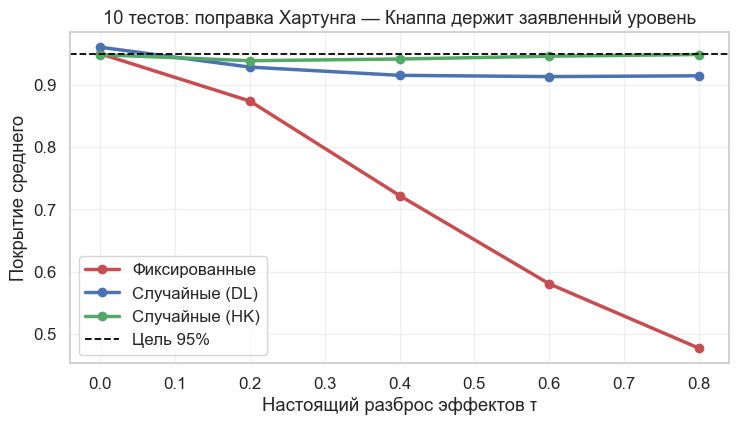

,Фиксированные,Случайные (DL),Случайные (HK)
0.0,0.950,0.961,0.949
0.2,0.874,0.929,0.939
0.4,0.722,0.916,0.942
0.6,0.580,0.914,0.946
0.8,0.477,0.915,0.949


In [3]:
taus = [0, 0.2, 0.4, 0.6, 0.8]
coverage = pd.DataFrame({tau: {name: values[0] for name, values in simulate_coverage(tau).items()} for tau in taus}).T

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for column, color in zip(coverage.columns, [RED, BLUE, GREEN]):
    ax.plot(coverage.index, coverage[column], 'o-', color=color, lw=2.5, label=column)
ax.axhline(0.95, color='black', ls='--', lw=1.3, label='Цель 95%')
ax.set_xlabel('Настоящий разброс эффектов τ')
ax.set_ylabel('Покрытие среднего')
ax.set_title('10 тестов: поправка Хартунга — Кнаппа держит заявленный уровень')
ax.legend()
plt.show()
coverage.round(3)

Модель фиксированных эффектов верна только при $\tau = 0$. При $\tau = 0.8$ её интервал накрывает среднее лишь в 48% случаев. DerSimonian — Laird с нормальным интервалом держится около 91–92%, а поправка Хартунга — Кнаппа даёт заявленные 94–95%. Её цена — более широкий интервал.

##### Выбор метода анализа

После выбора модели нужно выбрать метод анализа, который зависит от типа данных.

###### Мета-анализ для дихотомических исходов

При работе с бинарными исходами (событие произошло или нет) используют отношение шансов (Odds Ratio, OR), относительный риск (Relative Risk, RR) и разницу рисков (Risk Difference, RD).

Входные данные каждого исследования — таблица 2x2:

*   $a$: число событий в экспериментальной группе;
*   $b$: число объектов без события в экспериментальной группе;
*   $c$: число событий в контрольной группе;
*   $d$: число объектов без события в контрольной группе.

Эквивалентно можно использовать размеры групп ($n_e = a+b$, $n_c = c+d$) и доли событий ($p_e = a/n_e$, $p_c = c/n_c$).

**1. Метод Мантеля — Хензеля**

Есть набор таблиц 2x2 из разных исследований, и нужно получить одну обобщённую оценку. Метод Мантеля — Хензеля (MH) был создан для **анализа стратифицированных данных**, а в мета-анализе страты — это отдельные исследования.

Для $i$-го исследования нужны $a_i, b_i, c_i, d_i$ и общий размер $n_i = a_i + b_i + c_i + d_i$.

Другие методы считают OR в каждом исследовании и усредняют логарифмы. Мантель — Хензель **усредняет сами отношения шансов** с особыми весами $w_i^{MH} = b_i c_i / n_i$:

$$
\text{OR}_{\text{MH}} = \frac{\sum_{i=1}^k w_i^{\text{(MH)}} \cdot OR_i}{\sum_{i=1}^k w_i^{\text{(MH)}}} = \frac{\sum_{i=1}^k \frac{a_i d_i}{n_i}}{\sum_{i=1}^k \frac{b_i c_i}{n_i}}
$$

Числитель собирает пары, указывающие на рост шансов в экспериментальной группе, а знаменатель — пары, указывающие на снижение. Значение больше 1 означает, что событие в экспериментальной группе вероятнее.

Деление на $n_i$ приводит произведения к одной шкале: $a_i d_i$ растёт как квадрат размера исследования, а $a_i d_i / n_i$ — как размер. Поэтому большие исследования вносят больший вклад, но не квадратично. Такая формула устойчива при маленьких числах: нулевая ячейка в одном исследовании не ломает сумму, поэтому поправка на ноль не нужна.

Для относительного риска формула аналогична:

$$
\text{RR}_{\text{MH}} = \frac{\sum_{i=1}^k a_i (c_i + d_i) / n_i}{\sum_{i=1}^k c_i (a_i + b_i) / n_i}
$$

**2. Метод Пето**

Пусть изучается редкое побочное действие. В большинстве исследований событий нет, а там, где они есть, счёт идёт на единицы. Стандартные методы спотыкаются о нулевые ячейки. Метод Пето получает объединённое отношение шансов, сравнивая наблюдаемое число событий в экспериментальной группе с ожидаемым при отсутствии эффекта.

Для $i$-го исследования нужны те же $a_i, b_i, c_i, d_i$. Метод работает в три шага.

1.  **Отклонение.** Наблюдаемое $O_i = a_i$. Ожидаемое при отсутствии эффекта:

    $$
    E_i = \frac{n_{1i} m_{1i}}{N_i}
    $$

    где $n_{1i}$ — размер экспериментальной группы, $m_{1i}$ — общее число событий, $N_i$ — размер исследования. Отклонение равно $(O - E)_i$.

2.  **Дисперсия** отклонения:

    $$V_i = \frac{n_{1i} n_{2i} m_{1i} m_{2i}}{N_i^2 (N_i - 1)}$$

3.  **Оценка:**

    $$\ln(OR_{Peto}) = \frac{\sum (O - E)_i}{\sum V_i}$$

Метод не считает OR отдельных исследований, поэтому ему не мешают нулевые ячейки.

Но работает он только в определённых условиях. По [Брэдберну и соавторам (2007)](https://www.bibsonomy.org/bibtex/2e637e4988f9f47ea54c20116f8602340/jepcastel) при частоте событий ниже 1% метод Пето наилучший, **если группы примерно равны и эффект не очень велик**. Иначе он смещён. Проверим это: возьмём редкое событие и настоящий OR = 4.

In [4]:
def peto_or(a, n1, c, n2):
    m1, m2, n = a + c, n1 + n2 - a - c, n1 + n2
    expected = n1 * m1 / n
    variance = n1 * n2 * m1 * m2 / (n ** 2 * (n - 1))
    return np.exp(np.sum(a - expected) / np.sum(variance))


def mantel_haenszel_or(a, n1, c, n2):
    b, d, n = n1 - a, n2 - c, n1 + n2
    return np.sum(a * d / n) / np.sum(b * c / n)


def simulate_rare_events(true_or, ratio, base=0.01, trials=30, total=2000, reps=500, seed=1):
    """Сравнивает оценки OR при заданной доле экспериментальной группы."""
    local = np.random.default_rng(seed)
    n1 = int(total * ratio)
    n2 = total - n1
    risk = true_or * base / (1 - base + true_or * base)
    peto, mh = [], []
    for _ in range(reps):
        a, c = local.binomial(n1, risk, trials), local.binomial(n2, base, trials)
        peto.append(peto_or(a, n1, c, n2))
        mh.append(mantel_haenszel_or(a, n1, c, n2))
    return np.median(peto), np.median(mh)


rows = []
for true_or, ratio in [(1.5, 0.5), (1.5, 0.15), (4, 0.5), (4, 0.15), (10, 0.15)]:
    peto, mh = simulate_rare_events(true_or, ratio)
    rows.append({'Настоящий OR': true_or, 'Доля теста': ratio, 'Медиана Пето': peto, 'Медиана MH': mh})
pd.DataFrame(rows).round(2)

,Настоящий OR,Доля теста,Медиана Пето,Медиана MH
0,1.5,0.50,1.50,1.50
1,1.5,0.15,1.59,1.50
2,4.0,0.50,3.35,3.99
3,4.0,0.15,7.73,4.01
4,10.0,0.15,42.80,10.01


При равных группах и небольшом эффекте оба метода точны. При OR = 4 метод Пето занижает оценку до 3.35 даже при равных группах. При неравных группах он завышает: 7.7 при настоящих 4 и 43 при настоящих 10. Метод Мантеля — Хензеля остаётся точным. Поэтому сила метода Пето ограничена редкими событиями, равными группами и не очень большими эффектами.

###### Мета-анализ для непрерывных исходов

Для непрерывных исходов используют **разницу средних (Mean Difference, MD)** и **стандартизированную разницу средних (Standardized Mean Difference, SMD)**.

Для каждого исследования нужны размеры групп ($n_e$, $n_c$), средние ($\overline{Y}_e$, $\overline{Y}_c$) и стандартные отклонения ($s_e$, $s_c$).

**Разность средних (MD)**

MD используют, когда **исследования измеряют исход в одних единицах**:

$$\text{MD} = \overline{Y}_e - \overline{Y}_c$$

Стандартная ошибка считается через объединённое стандартное отклонение $s_p$:

$$
\text{SE}_{\text{MD}} = s_p \sqrt{\frac{1}{n_e} + \frac{1}{n_c}}, \qquad s_p = \sqrt{\frac{(n_e-1)s_e^2 + (n_c-1)s_c^2}{n_e+n_c-2}}
$$

**Стандартизированная разность средних (SMD)**

SMD используют, когда **разные исследования измеряют один конструкт разными шкалами**. Результаты выражаются в стандартных отклонениях и поэтому сопоставимы.

*   **Cohen's d** — разность средних, делённая на объединённое стандартное отклонение:

    $$d = \frac{\overline{Y}_e - \overline{Y}_c}{s_p}$$

*   **Glass's Δ** отличается только тем, что делит на стандартное отклонение контрольной группы. Это полезно, если воздействие меняет разброс.

*   **Hedges' g** — это $d$ с поправкой на смещение. На малых выборках $d$ завышает эффект, поэтому её умножают на коэффициент:

    $$g = d \left(1 - \frac{3}{4m - 1}\right), \qquad m = n_e + n_c - 2$$

В книге Хеджеса и Олкина и в некоторых конспектах обозначения обратные: $g$ для исходной оценки и $d$ для исправленной. При чтении источников это стоит проверять.

Стандартная ошибка:

$$
\text{SE}_{\text{SMD}} = \sqrt{\frac{n_e+n_c}{n_e n_c} + \frac{\text{SMD}^2}{2(n_e+n_c)}}
$$

#### Регрессионный мета-анализ

Мета-регрессия **использует регрессионный анализ для объединения результатов исследований** с учётом ковариат (модераторов). Она показывает, как категориальные и непрерывные модераторы влияют на размер эффекта.

Модель фиксированных эффектов для $i$-го исследования:

$$
y_i = x_i'\beta + \epsilon_i, \qquad \epsilon_i \sim N(0, v_i)
$$

где $y_i$ — размер эффекта, $x_i$ — вектор ковариат, $v_i$ — дисперсия оценки. Коэффициенты $\beta$ показывают, как изменение модератора влияет на эффект.

Модель со случайными эффектами добавляет межисследовательский разброс $u_i \sim N(0, \tau^2)$:

$$
y_i = x_i'\beta + u_i + \epsilon_i
$$

Обычно используют взвешенную регрессию с весами $1/(v_i + \tau^2)$.

Здесь есть ловушка: `WLS` по умолчанию оценивает масштаб остатков. В мета-регрессии дисперсии $v_i$ известны, поэтому масштаб должен быть зафиксирован на единице. В `statsmodels` это делается аргументом `scale=1` у метода `fit`.

Ещё две оговорки. Мета-регрессия — наблюдательный анализ на уровне исследований: связь между средними не обязательно верна для отдельных пользователей. И она требует достаточно исследований: обычно хотят хотя бы 10 на одну ковариату.

Пример: у нас есть 25 A/B-тестов одной фичи, а эффект зависит от доли новых пользователей в тесте. Настоящий наклон равен 2.

Оценка τ²: 0.013
Наклон: 1.94, SE с фиксированным масштабом: 0.295, SE по умолчанию: 0.295


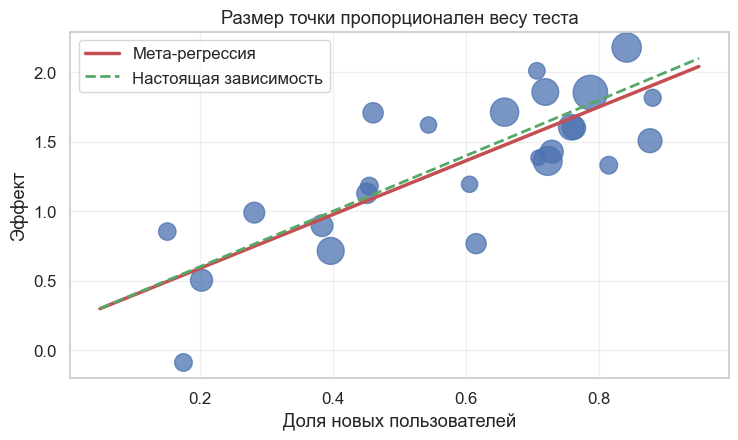

In [5]:
k = 25
new_users = rng.uniform(0.1, 0.9, k)
variances = rng.uniform(0.02, 0.2, k)
effects = rng.normal(0.2 + 2 * new_users, np.sqrt(variances + 0.05))

design = sm.add_constant(new_users)
residual_fit = sm.WLS(effects, design, weights=1 / variances).fit()
residuals = effects - design @ residual_fit.params
q = np.sum(residuals ** 2 / variances)
c = np.sum(1 / variances) - np.trace(np.linalg.solve(design.T @ (design / variances[:, None]), design.T @ (design / (variances ** 2)[:, None])))
tau2 = max(0, (q - (k - 2)) / c)

weights = 1 / (variances + tau2)
meta_fit = sm.WLS(effects, design, weights=weights).fit(scale=1)
default_fit = sm.WLS(effects, design, weights=weights).fit()
print(f'Оценка τ²: {tau2:.3f}')
print(f'Наклон: {meta_fit.params[1]:.2f}, SE с фиксированным масштабом: {meta_fit.bse[1]:.3f}, SE по умолчанию: {default_fit.bse[1]:.3f}')

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(new_users, effects, s=weights * 25, color=BLUE, alpha=0.75)
grid = np.array([0.05, 0.95])
ax.plot(grid, meta_fit.params[0] + meta_fit.params[1] * grid, color=RED, lw=2.5, label='Мета-регрессия')
ax.plot(grid, 0.2 + 2 * grid, color=GREEN, ls='--', lw=2, label='Настоящая зависимость')
ax.set_xlabel('Доля новых пользователей')
ax.set_ylabel('Эффект')
ax.set_title('Размер точки пропорционален весу теста')
ax.legend();

Здесь две стандартные ошибки совпали, потому что оценка $\tau^2$ сама подгоняет масштаб остатков к единице. Если веса заданы без верного $\tau^2$, они разойдутся, поэтому `scale=1` стоит указывать явно.

### Синтез значимостей

Мета-анализ становится особенно полезным в нескольких ключевых сценариях:

*   **Для подтверждения сильных эффектов:** Если несколько тестов с общей гипотезой показывают статистически значимый и положительный эффект в одном направлении, мета-анализ лишь ещё больше убеждает в наличии эффекта и позволяет увереннее внедрять инициативы.
*   **Для выявления скрытых эффектов:** Одна из наиболее интересных и ценных ситуаций, когда мета-анализ проявляет себя, это когда отдельные тесты **не достигают статистической значимости (p-value находится у порога значимости), но при этом абсолютно все указывают на лучшее состояние нового дизайна или фичи**. Например, если два независимых теста дают p-value = [0.051, 0.051], по отдельности они не позволяют отклонить нулевую гипотезу, но их комбинация кажется крайне маловероятной случайностью. Мета-анализ позволяет проверить, можно ли отклонить нулевую гипотезу, рассматривая эти p-value вместе.


Но спешить мета-анализировать тесты не стоит. Важны несколько условий.

* Во-первых, тесты должны быть согласованы. Иначе можно обобщить пилоты, одинаковые по названию, но разные по смыслу.

* Во-вторых, надо сохранять сравнимость групп из теста в тест: рандомизация должна быть внутри каждого теста, а аудитории близкими.

* В-третьих, важно, участвуют ли люди из параллельного или предыдущего теста в другом тесте с той же $H_0$. От этого зависит, независимы ли статистики.

И главное: **комбинация p-value отвечает на вопрос о значимости, а не о размере эффекта**. Общая нулевая гипотеза здесь — «эффекта нет ни в одном тесте». Её отклонение означает, что эффект есть хотя бы в одном тесте, а не во всех.

* **Независимая общая  $H_0$**

  Это когда у нас из теста в тест фичи идёт разная конфигурация юзеров/объектов в A/B. В этом случае мы работаем с комбинацией статистик/p-value (и вероятностью таковую получить, если верна $H_0$). Для этого случая мы рассмотрим метод комбинированной вероятности Фишера (Fisher's method, Fisher's combined probability test) и метод weighted z-score (Stouffer's, Liptak).

* **Зависимая общая $H_0$**

  Это когда из теста в тест пользователи могут повторяться, и статистики связаны между собой. В этом случае рассмотрим метод взвешенного гармонического среднего (weighted harmonic mean p-value).

#### Метод Фишера (Fisher's method, Fisher's combined probability test)

Метод предложил Рональд Фишер в 1934 году. Мы знаем, что когда верна $H_0$, теоретическое p-value имеет вид равномерного распределения. Пускай мы провели 2 теста подряд, когда верна $H_0$, получив следующую комбинацию p-values = [0.05, 0.9]. Проведём ещё два теста подряд (когда верна $H_0$), получим новую комбинацию = [0.6, 0.7]. Отразим на графике, где первое p-value по оси $X$ от первого теста, а второе по оси $Y$ – от второго:

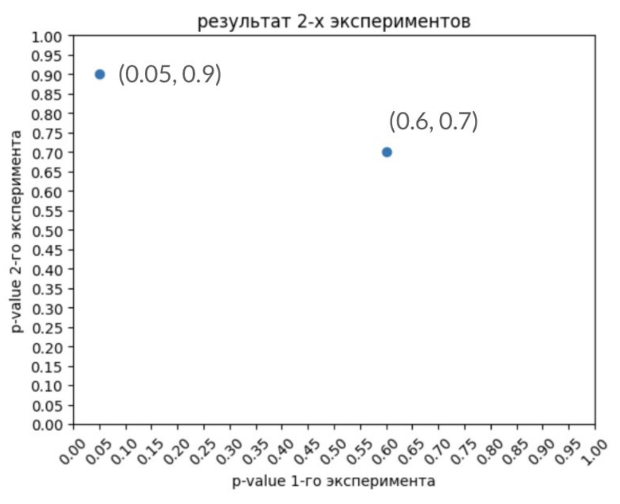

Где 2 комбинации, там и 100500 комбинаций:

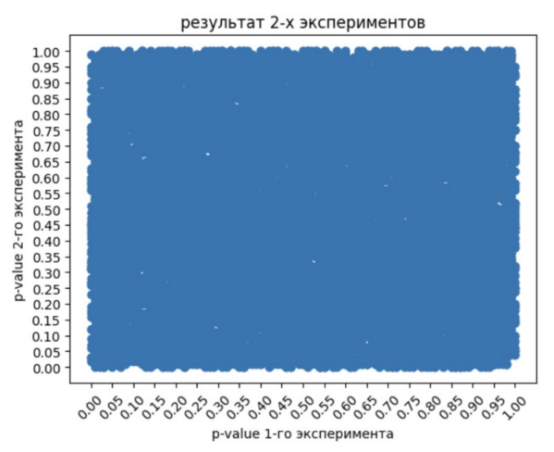

Получаем равномерно заполненный квадрат.

Вернёмся к комбинации = [0.05, 0.9]. Какие комбинации можно получить с такой же или меньшей вероятностью?

Ответ: такие комбинации, которые при перемножении p-value's будут равны или меньше, чем 0.05*0.9 = 0.045. Почему перемножение? Да как раз потому, что у нас два независимых события со своими вероятностями, и мы смотрим совместное их появление. Всё по классической теории вероятности.

Итак, что ещё даст значение, равное или меньше, чем 0.045? Например, конечно, точка [0.9, 0.05] (выделена красным):

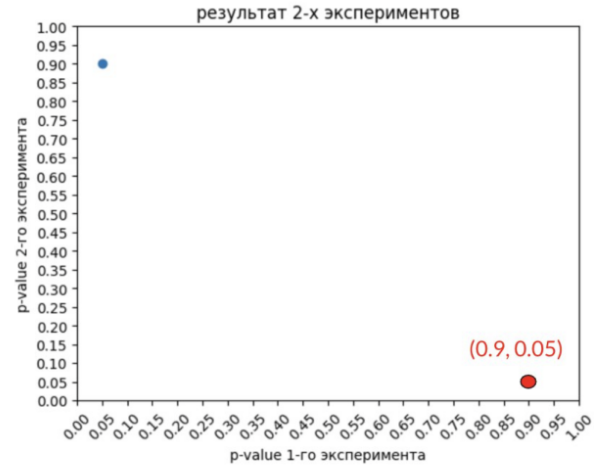

Какие ещё пары дают произведение не больше 0.045?

* Например, если будем уменьшать только первое p-value: 0.04*0.9

* Если будем уменьшать только второе p-value: 0.05*0.89

* Если будем уменьшать оба p-value: 0.04*0.89

* Если будем первое p-value увеличивать, а второе p-value уменьшать (до некоторого предела, конечно): 0.18*0.25

Тогда все точки (комбинации), которые удовлетворяют этим условиям на нашем графике 100 500 комбинаций будут следующими, выделены красным:

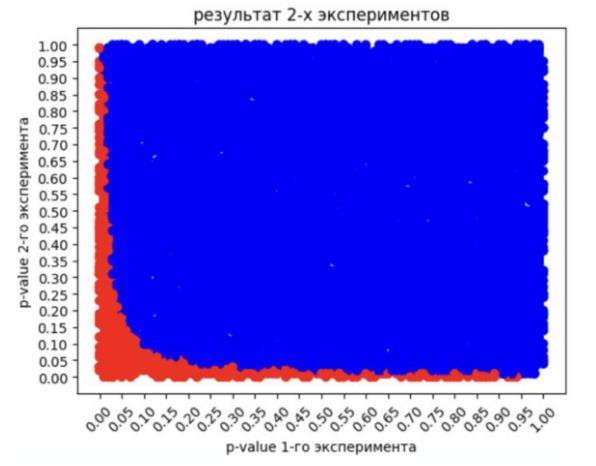

Далее нам нужно рассчитать долю красных точек против всех точек (и красных, и синих):

$p_{[0.05, 0.9]}=\frac{\text{red}}{\text{red}+\text{blue}}\simeq 0.18$

Это и есть p-value нашего с вами мета-анализа комбинации [0.05, 0.9].
Вернёмся к случаю с [0.051, 0.051]. Вот наш результат, мета-pvalue в картинке:

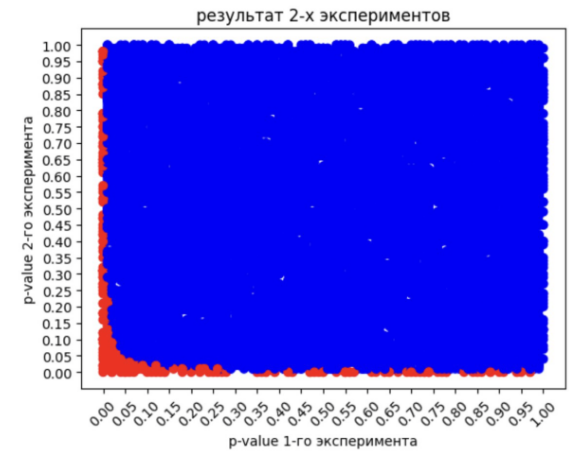

P[0.051, 0.051] = 0.018, то есть стат. значимый результат! Интерпретация такого “мета p-value” следующая – вероятность получить такую вероятность совместных событий (p-value) при условии верности общей $H_0$.

На картинке выше видно, какую долю от H0 составляет такая комбинация: действительно, очень небольшую! Что бьётся с нашей интуицией о малой вероятности случайности такого исхода.

На википедии есть очень выразительная картинка для комбинации из двух p-value:

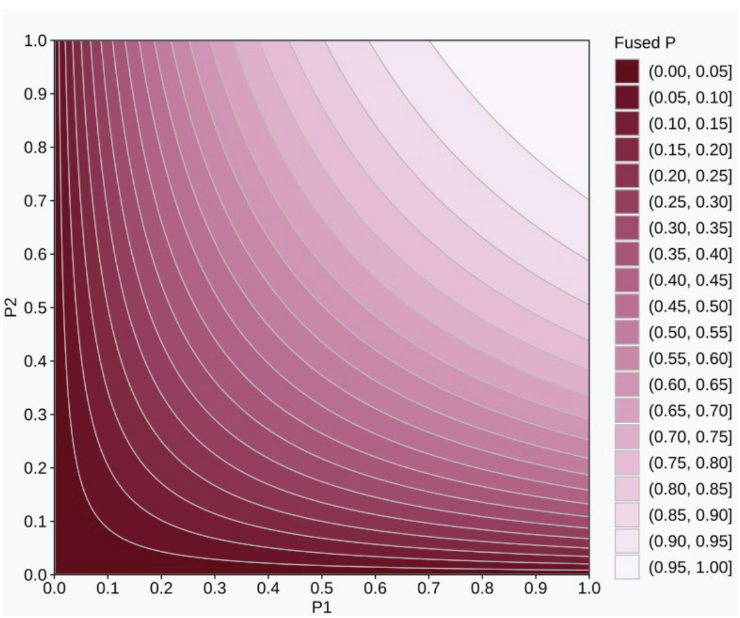

Но не всё так просто, к сожалению. Дело в том, что таким подходом можно пользоваться лишь при незначительном объёме экспериментов. Если количество экспериментов будет расти, то:

* При расчёте методом Монте-Карло нам понадобится много ресурсов на генерацию множества вариантов.

* При аналитическом расчёте также понадобится много вычислительных ресурсов, так как интегралы будут многомерными.

Именно поэтому Фишер предложил универсальный способ, основанный на свойстве распределения Хи-квадрат:

Произведение p-value неудобно само по себе: при каждом числе тестов у него своё распределение. Но **сумма независимых величин $\chi^2$ сама распределена как $\chi^2$**. Поэтому Фишер превратил каждое p-value в такую величину: если взять **натуральный логарифм p-value, изменить знак и удвоить**, получится $\chi^2$ с **2 степенями свободы**.

Математически это выглядит так:
* Для равномерно распределенной случайной величины p, случайная величина **-2 ln(p)** будет иметь **экспоненциальное распределение**, которое является частным случаем **$\chi^2$ распределения с 2 степенями свободы**.
* Если у нас есть *k* независимых p-value ($p₁, p₂, ..., pₖ$), каждое из которых преобразовано в $\chi^2$ с 2 степенями свободы, то их сумма - $X² = -2 \sum ln(pᵢ)$.
* Эта суммарная статистика $\chi^2$ будет распределена как **$\chi^2$ с 2k степенями свободы**.
* Полученное значение $\chi^2$ сравнивается с критическими значениями $\chi^2$ распределения с 2k степенями свободы.

В нашем примере расчёт происходил бы так:
*   Для $p₁ = 0.051: -2 * ln(0.051) ≈ -2 * (-2.976) ≈ 5.952$
*   Для $p₂ = 0.051: -2 * ln(0.051) ≈ 5.952$
*   Суммарная статистика $\chi^2 = 5.952 + 5.952 = 11.904$
*   Количество степеней свободы = 2 * $k$ = 2 * 2 = 4
*   Значение $\chi^2 = 11.904$ с 4 степенями свободы даёт мета p-value **0.018**.


Несмотря на свою полезность, метод Фишера имеет несколько важных ограничений:
*   **Не учитывает направление эффекта**: Он оперирует только p-value без привязки к абсолютному значению или направлению разницы между группами. Это означает, что мета-p-value может быть статистически значимым, даже если в одном тесте B оказался лучше A, а в другом — хуже. Интерпретация такого результата становится проблематичной.
*   **Не учитывает разный объем выборок в базовой форме**: в формуле нет весов. Хотя есть обобщения с весами, для таких случаев обычно используют другие методы.
*   **Требует независимости тестов.** Если тесты зависимы, метод сильно завышает значимость, и мы увидим это ниже.

In [6]:
pairs = rng.random((1_000_000, 2))
for pair in [(0.05, 0.9), (0.051, 0.051)]:
    product = np.prod(pair)
    monte_carlo = np.mean(pairs.prod(axis=1) <= product)
    analytic = product * (1 - np.log(product))
    print(f'{pair}: Монте-Карло {monte_carlo:.4f}, формула {analytic:.4f}, scipy {st.combine_pvalues(pair, "fisher").pvalue:.4f}')

(0.05, 0.9): Монте-Карло 0.1843, формула 0.1845, scipy 0.1845
(0.051, 0.051): Монте-Карло 0.0180, формула 0.0181, scipy 0.0181


Все три способа совпали с числами на картинках.

#### Метод Weighted Z-score

Другой подход к объединению тестов предложил Стоуффер (1949), а затем развили Липтак (1958), Уитлок (2005) и Зайкин (2011).

Метод **учитывает статистику и размер выборки в каждом тесте** и сохраняет знак. Поэтому эффекты в разные стороны взаимно компенсируются. Каждое одностороннее p-value превращается в $z$-оценку, и они складываются с весами:

$$Z_{combined} = \frac{\sum_{i=1}^{k} w_i z_i}{\sqrt{\sum_{i=1}^{k} w_i^2}}$$

где $w_i$ — вес $i$-го теста, $z_i$ — его $z$-статистика. При независимых тестах $Z_{combined}$ стандартно нормальна, поэтому результат легко интерпретировать. Рекомендуемый вес равен $\sqrt{n_i}$.

Такой тест отвечает на вопрос о значимости, но чаще нужна ещё и оценка эффекта с интервалом. Если объединить средние с весами $\pi_i = n_i / \sum n_j$:

1.  **Комбинированная дельта:**
    $$\Delta = \sum_{i=1}^{k} \pi_i \Delta_i$$
2.  **Стандартная ошибка:**
    $$SE_{combined} = \sqrt{\sum_{i=1}^{k} \pi_i^2 SE_i^2}$$
3.  **Доверительный интервал:**
    $$[\Delta - z_{\alpha/2} SE_{combined}, \quad \Delta + z_{\alpha/2} SE_{combined}]$$

Здесь важен выбор веса. Если $SE_i \propto 1/\sqrt{n_i}$, то $z$-статистика, полученная из этого $\Delta$, совпадает со $Z_{combined}$ с весами $\sqrt{n_i}$. То есть вес $\sqrt{n}$ в формуле $Z$ соответствует весу $n$ для самой дельты. Если использовать $\sqrt{n}$ и там, и там, интервал и тест разойдутся. Проверим это.

In [7]:
sizes = np.array([20_000, 5_000, 40_000, 10_000], dtype=float)
sigma = 1.0
se_tests = sigma * np.sqrt(2 / sizes)
deltas = np.array([0.02, 0.05, 0.015, 0.03])
z_tests = deltas / se_tests

weights_sqrt = np.sqrt(sizes)
z_stouffer = np.sum(weights_sqrt * z_tests) / np.sqrt(np.sum(weights_sqrt ** 2))


def pooled_z(weights):
    normalized = weights / weights.sum()
    return np.sum(normalized * deltas) / np.sqrt(np.sum(normalized ** 2 * se_tests ** 2))


print(f'Z Стоуффера с весами sqrt(n):          {z_stouffer:.4f}')
print(f'Z из комбинированной дельты, веса n:   {pooled_z(sizes):.4f}')
print(f'Z из комбинированной дельты, веса sqrt(n): {pooled_z(weights_sqrt):.4f}')
print(f'Равные веса, Стоуффер, p для [0.051, 0.051]: {st.combine_pvalues([0.051, 0.051], "stouffer").pvalue:.4f}')
print(f'Фишер для тех же значений:                  {st.combine_pvalues([0.051, 0.051], "fisher").pvalue:.4f}')

Z Стоуффера с весами sqrt(n):          4.0021


Z из комбинированной дельты, веса n:   4.0021
Z из комбинированной дельты, веса sqrt(n): 4.3713
Равные веса, Стоуффер, p для [0.051, 0.051]: 0.0104
Фишер для тех же значений:                  0.0181


С весами $n$ для дельты всё совпадает, а с $\sqrt{n}$ нет. Заодно видно, что методы Фишера и Стоуффера **не совпадают** даже при равных весах: 0.018 и 0.010.

Какой из них мощнее, зависит от картины. Сравним на симуляции 5 равных по размеру тестов: в первом сценарии эффект есть во всех тестах, во втором только в одном, в третьем в двух с разным знаком.

In [8]:
def combined_power(effects, reps=40_000, alpha=0.05, seed=2):
    """Считает долю отклонений общей H0 для каждого метода."""
    local = np.random.default_rng(seed)
    z = local.normal(np.asarray(effects), 1, (reps, len(effects)))
    p = st.norm.sf(z)
    fisher = st.chi2.sf(-2 * np.log(p).sum(axis=1), 2 * len(effects))
    stouffer = st.norm.sf(z.sum(axis=1) / np.sqrt(len(effects)))
    harmonic = len(effects) / (1 / p).sum(axis=1)
    return (fisher < alpha).mean(), (stouffer < alpha).mean(), (harmonic < alpha).mean()


scenarios = {'Эффект 1 во всех 5 тестах': [1] * 5, 'Эффект 3 только в одном': [3, 0, 0, 0, 0], 'Эффекты 3 и -3': [3, -3, 0, 0, 0], 'Эффекта нет': [0] * 5}
pd.DataFrame({name: combined_power(effects) for name, effects in scenarios.items()}, index=['Фишер', 'Стоуффер', 'HMP']).T.round(3)

,Фишер,Стоуффер,HMP
Эффект 1 во всех 5 тестах,0.676,0.722,0.495
Эффект 3 только в одном,0.656,0.381,0.785
Эффекты 3 и -3,0.553,0.050,0.777
Эффекта нет,0.049,0.050,0.060


Если эффект небольшой и есть во всех тестах, Стоуффер мощнее: 0.72 против 0.68. Если эффект сильный, но только в одном тесте, Фишер мощнее: 0.66 против 0.38. При эффектах 3 и -3 Стоуффер даёт ровно 5%, потому что они компенсируются, а Фишер отклоняет $H_0$ в 55% случаев, хотя в среднем эффекта нет. HMP реагирует на самый сильный тест и при равномерно слабом эффекте теряет мощность. Вывод [Уитлока (2005)](https://scilit.com/publications/ab05b8b6dc9402262c9851a832654a7f) о превосходстве взвешенного Z относится именно к случаю общего эффекта. При верной $H_0$ HMP с порогом 0.05 слегка превышает уровень: 6%.

Метод Стоуффера привычнее для сравнения средних, сохраняет знак и связан с доверительным интервалом для эффекта. Метод Фишера удобнее для других критериев и сильнее реагирует на один резкий результат.

#### Harmonic Mean p-value

Метод гармонического среднего p-значения (HMP) предложил Дэниел Уилсон в 2019 году. Он нужен, когда **тесты могут быть зависимы**.

Например, тест не дал значимости, его повторили, и часть пользователей попала в новый тест. P-value этих тестов теперь связаны. Комбинировать их методом Фишера нельзя.

Вывод HMP опирается на правдоподобие. Если у нас есть $L$ тестов с отношениями правдоподобий $R_l$, то среднее $\frac{1}{L}\sum R_l$ можно приблизить через p-value, потому что при определённых условиях $p \approx 1/R$. Подстановка даёт гармоническое среднее:

$$p_{0} = \frac{1}{\sum_{i=1}^{L} \frac{w_i}{p_i}}$$

где $p_i$ — p-значение $i$-го теста, $w_i$ — нормализованный вес, $\sum w_i = 1$. Вес может отражать размер выборки или важность метрики.

**HMP нельзя читать как обычный p-value.** При малых значениях он близок к нему, при больших сильно занижен, для точного расчёта есть отдельные таблицы. Уилсон выводил метод в предположении независимости или слабой зависимости. [Гёман, Розенблатт и Николс (2019)](https://pmc.ncbi.nlm.nih.gov/articles/PMC6876242) показали, что при произвольной зависимости гарантии уровня нет, и если её требовать, то поправка Бонферрони мощнее и надёжнее. [Вовк и Ван (2020)](https://arxiv.org/abs/1212.4966) показали, что под произвольной зависимостью гарантию даёт $e \ln(L) \cdot HMP$.

Проверим на симуляции, сколько раз каждый метод ошибается при верной $H_0$, если тесты коррелируют.

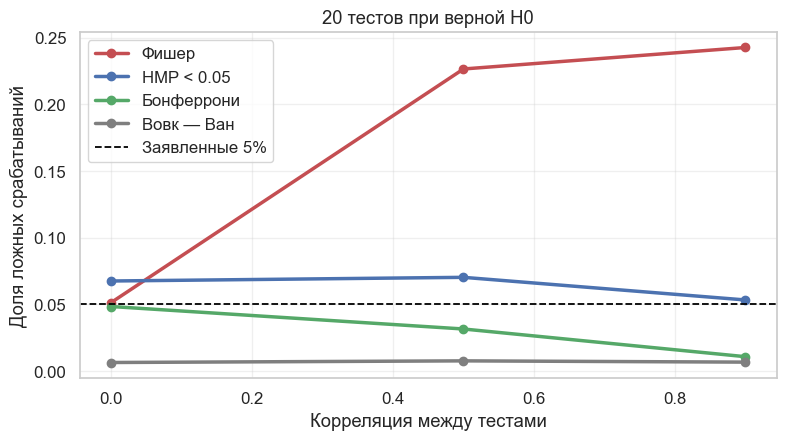

,Число тестов,Корреляция,Фишер,HMP < 0.05,Бонферрони,Вовк — Ван
0,5,0.0,0.049,0.060,0.049,0.012
1,5,0.5,0.124,0.060,0.039,0.013
2,5,0.9,0.153,0.052,0.022,0.012
3,20,0.0,0.051,0.068,0.048,0.006
4,20,0.5,0.227,0.070,0.032,0.008
5,20,0.9,0.243,0.053,0.011,0.007
6,100,0.0,0.052,0.077,0.049,0.004
7,100,0.5,0.315,0.079,0.025,0.005
8,100,0.9,0.309,0.054,0.004,0.004


In [9]:
def error_rates(tests, rho, reps=100_000, alpha=0.05, seed=1):
    """Считает долю ложных срабатываний при верной H0 для коррелированных тестов."""
    local = np.random.default_rng(seed)
    z = np.sqrt(rho) * local.normal(size=(reps, 1)) + np.sqrt(1 - rho) * local.normal(size=(reps, tests))
    p = st.norm.sf(z)
    harmonic = tests / (1 / p).sum(axis=1)
    return {'Число тестов': tests, 'Корреляция': rho,
            'Фишер': (st.chi2.sf(-2 * np.log(p).sum(axis=1), 2 * tests) < alpha).mean(),
            'HMP < 0.05': (harmonic < alpha).mean(),
            'Бонферрони': (p.min(axis=1) < alpha / tests).mean(),
            'Вовк — Ван': (harmonic * np.e * np.log(tests) < alpha).mean()}


errors = pd.DataFrame([error_rates(tests, rho) for tests in [5, 20, 100] for rho in [0, 0.5, 0.9]])

fig, ax = plt.subplots(figsize=(9, 4.5))
part = errors.query('`Число тестов` == 20')
for column, color in zip(['Фишер', 'HMP < 0.05', 'Бонферрони', 'Вовк — Ван'], [RED, BLUE, GREEN, GRAY]):
    ax.plot(part['Корреляция'], part[column], 'o-', color=color, lw=2.5, label=column)
ax.axhline(0.05, color='black', ls='--', lw=1.3, label='Заявленные 5%')
ax.set_xlabel('Корреляция между тестами')
ax.set_ylabel('Доля ложных срабатываний')
ax.set_title('20 тестов при верной H0')
ax.legend()
plt.show()
errors.round(3)

Метод Фишера при зависимых тестах разрушается: вместо 5% ложных срабатываний получается от 12% до 32%. HMP с порогом 0.05 слегка превышает заявленный уровень: 5–8%, и при независимых тестах тоже, поэтому он близок к цели, но не гарантирует её. Бонферрони всегда укладывается в 5% и становится консервативным при сильной корреляции. Вариант Вовка — Вана самый надёжный и самый консервативный.

HMP полезен, если нужна общая оценка по связанным тестам или метрикам. Но он не спасает от подглядывания: нельзя повторять тест, пока он не «прокрасится», а затем объединять. Для этого есть последовательные методы из лекции 2.01. Комбинировать нужно все проведённые тесты, а не только удачные.

## Визуализация и интерпретация графиков

В мета-анализе используются несколько визуализаций для представления данных и обнаружения потенциальных проблем. Две основные и наиболее часто используемые визуализации — это воронкообразные графики (funnel plots) и лесные графики (forest plots). Также могут использоваться гистограммы распределения размеров эффекта и двумерные таблицы для изучения модераторов.

**1. Воронкообразный график (Funnel Plot)**

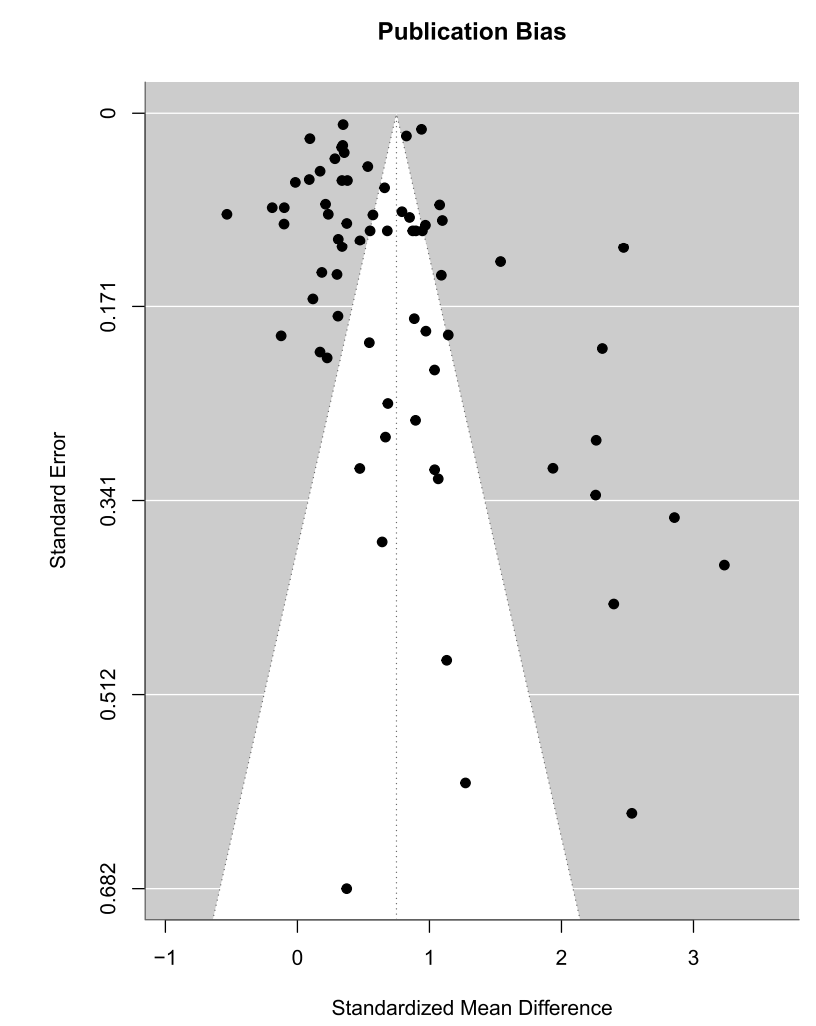


Воронкообразный график — это график, предназначенный для проверки наличия **публикационного смещения (publication bias)**. Он часто используется в систематических обзорах и мета-анализах.

**Компоненты и интерпретация:**
*   **Оси:**
    *   **Ось Y:** Представляет **точность исследования** (study precision), например, обратную стандартную ошибку или количество экспериментальных субъектов. Чем выше значение на оси Y, тем выше точность исследования. Рекомендуется использовать стандартную ошибку.
    *   **Ось X:** Показывает **результат исследования** (treatment effect measure), например, измеренный средний эффект препарата. График традиционно рисуется с мерой эффекта лечения на горизонтальной оси, что облегчает интерпретацию асимметрии.
*   **Расположение точек:** Каждая точка на графике представляет отдельное исследование.
*   **Идеальная форма (отсутствие смещения):** В отсутствие публикационного смещения предполагается, что исследования с высокой точностью будут располагаться близко к среднему значению, а исследования с низкой точностью будут равномерно распределены по обе стороны от среднего, образуя приблизительно **форму перевернутой воронки**. Симметричная перевернутая воронка указывает на «хорошо себя ведущий» набор данных, в котором публикационное смещение маловероятно.
*   **Отклонение от формы (наличие смещения):** **Отклонение от воронкообразной формы может указывать на публикационное смещение**. Асимметричная воронка предполагает взаимосвязь между оценкой эффекта лечения и точностью исследования. Это может указывать на публикационное смещение или систематическое различие между исследованиями высокой и низкой точности (так называемые «эффекты малых исследований»). Асимметрия также может возникнуть из-за использования неподходящей меры эффекта.


**Критика воронкообразных графиков:**
*   Могут создавать ложное впечатление о публикационном смещении, если точные исследования отличаются от неточных по размеру эффекта, например из-за разных популяций.
*   Вид графика может значительно меняться в зависимости от шкалы на оси Y (например, обратная квадратная ошибка или размер выборки).
*   Исследователи плохо справляются с визуальным распознаванием публикационного смещения по воронкообразным графикам.

**2. Лесной график (Forest Plot)**

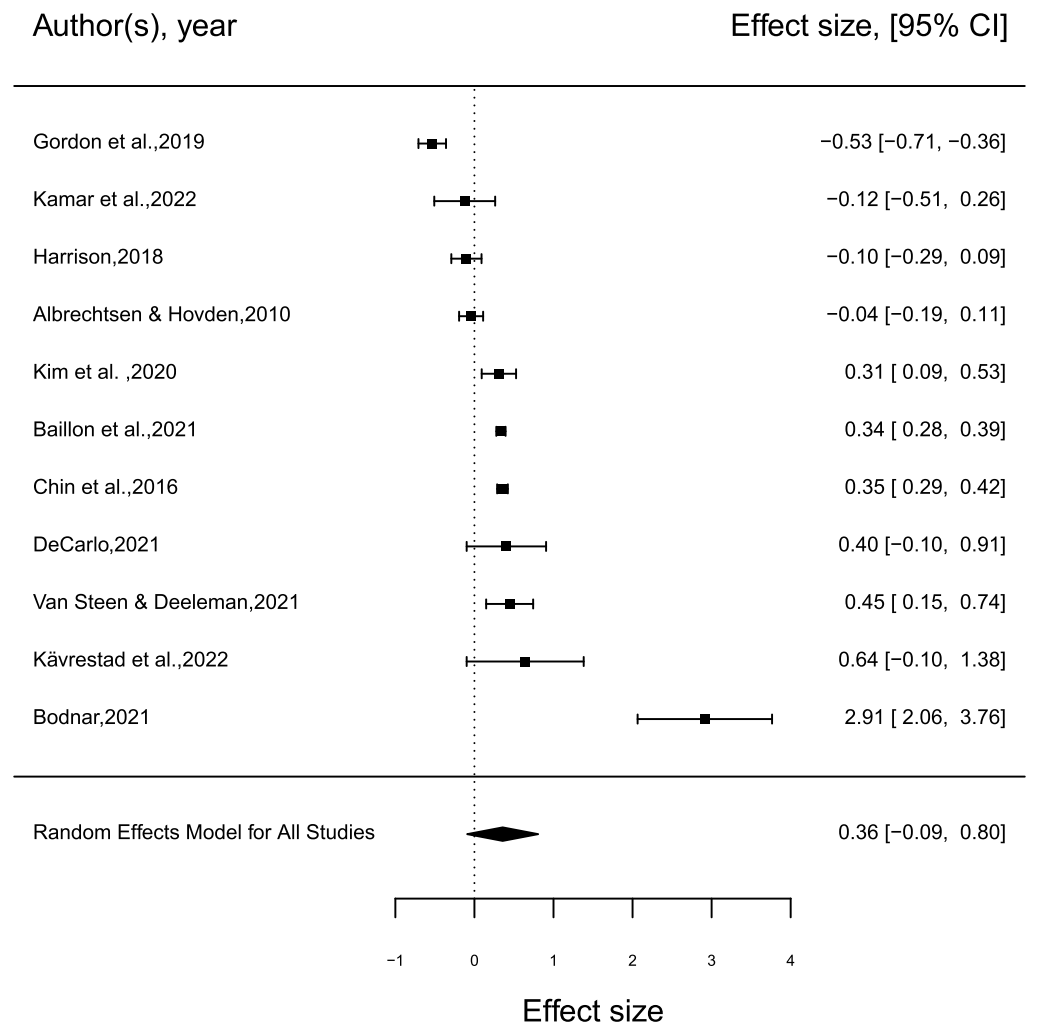

Лесной график — это тип графика, используемый в исследованиях для отображения **результатов одной темы из нескольких исследований построчно**. Он позволяет легко увидеть вариации и тенденции в отношении вмешательства или лечения. Лесные графики обеспечивают способ отображения большинства результатов мета-анализа в одной фигуре.

**Компоненты и интерпретация:**
*   **Метки исследований (Study Labels):** Расположены в левой части графика, идентифицируют каждое соответствующее исследование и содержат имя автора исследования и год.
*   **Размер эффекта (Effect Size):** Представляет наблюдаемый эффект результата в каждом исследовании. Он отображается **точкой (или квадратом/прямоугольником/кругом)**. Положение точки на графике указывает, является ли эффект отрицательным, нейтральным или положительным.
    *   Для относительных мер (RR, OR) значение 1 означает отсутствие эффекта, и график обычно строят на логарифмической шкале.
    *   Для разностей (MD, SMD) отсутствию эффекта соответствует 0.
*   **Доверительные интервалы (Confidence Intervals - CI):** Каждое исследование показывает **горизонтальную линию**, отображающую диапазон возможных результатов. Более узкая линия указывает на более высокую точность размера эффекта.
*   **Линия отсутствия эффекта (No Effect Line):** Это **вертикальная линия**, представляющая отсутствие эффекта (либо ноль, либо единица, в зависимости от используемой меры эффекта).
    *   **Если доверительный интервал исследования пересекает эту линию:** Исследование не является статистически значимым.
    *   **Если доверительный интервал исследования не пересекает эту линию:** Исследование обнаружило статистически значимый эффект.
*   **Общий эффект (Overall Effect - Diamond Shape):** Расположен в нижней части графика, представлен **алмазообразной фигурой**, суммирующей все результаты исследований (объединенный эффект). Центр алмаза показывает общий эффект, а ширина алмаза представляет его доверительный интервал.
    *   **Если алмаз не пересекает линию отсутствия эффекта:** Объединенный результат является статистически значимым.
    *   **Если алмаз пересекает линию отсутствия эффекта:** Общего эффекта нет, или он не статистически значим.
*   **Согласованность исследований:** Если все линии (доверительные интервалы) расположены близко друг к другу, это означает, что исследования согласуются по данной теме; в противном случае существуют различные выводы.

**Воронка и публикационное смещение**

Посмотрим, как смещение появляется на графике. Пусть настоящий эффект равен нулю, но незначимые положительные и все отрицательные тесты публикуются только с некоторой вероятностью. Подвигайте эту вероятность.

In [10]:
def simulate_publication(publish_rate, effect=0.0, k=300, seed=5):
    """Моделирует отбор тестов: значимые положительные публикуются всегда."""
    local = np.random.default_rng(seed)
    se = local.uniform(0.03, 0.4, k)
    y = local.normal(effect, se)
    significant = y / se > 1.96
    published = significant | (local.random(k) < publish_rate)
    return y, se, published


def plot_funnel(ax, publish_rate):
    y, se, published = simulate_publication(publish_rate)
    estimate, _, _ = fixed_effect(y[published], se[published] ** 2)
    plain = y[published].mean()
    grid = np.array([0, 0.42])
    ax.scatter(y[~published], se[~published], s=16, color=GRAY, alpha=0.3, label='Не опубликовано')
    ax.scatter(y[published], se[published], s=22, color=BLUE, label='Опубликовано')
    ax.plot(1.96 * grid, grid, color=RED, ls='--', lw=1.5)
    ax.plot(-1.96 * grid, grid, color=RED, ls='--', lw=1.5)
    ax.axvline(0, color='black', lw=1.3)
    ax.axvline(estimate, color=GREEN, lw=2.5, label=f'Мета-оценка {estimate:.3f}')
    ax.axvline(plain, color=RED, lw=2.5, label=f'Простое среднее {plain:.3f}')
    ax.invert_yaxis()
    ax.set_xlabel('Эффект')
    ax.set_ylabel('Стандартная ошибка')
    ax.set_title(f'Публикуется {publish_rate:.0%} незначимых', fontsize=12)
    ax.legend(fontsize=10)


def funnel_demo(publish_rate=0.2):
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    plot_funnel(ax, publish_rate)
    plt.show()


interact(funnel_demo, publish_rate=FloatSlider(value=0.2, min=0, max=1, step=0.1, description='Доля'));

Статичная версия для трёх долей.

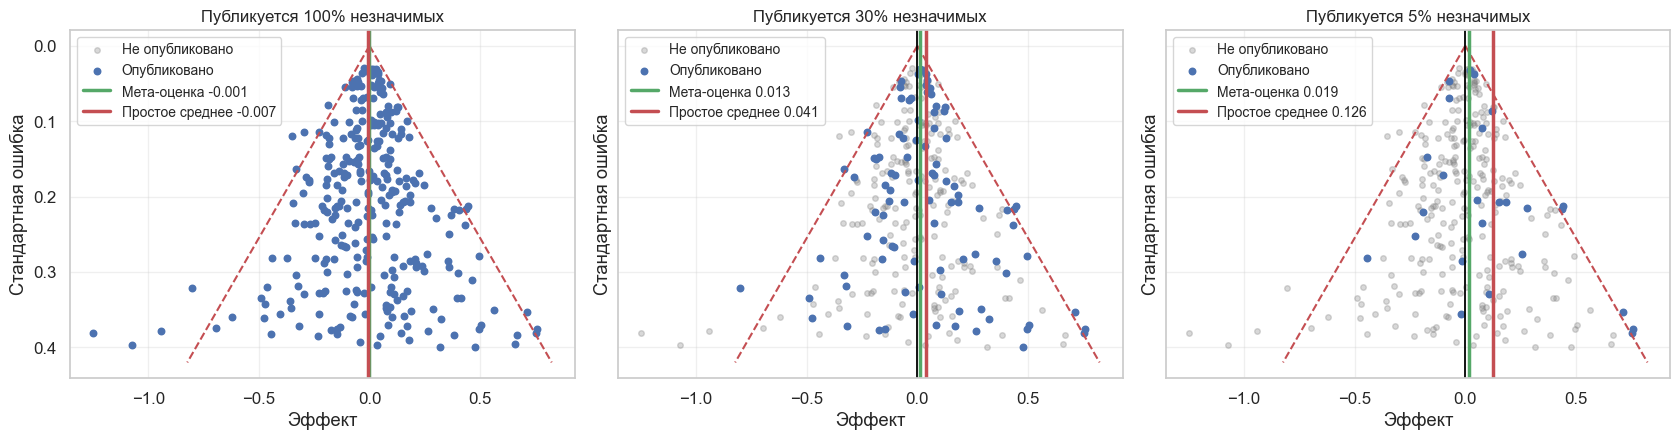

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True, sharex=True)
for ax, rate in zip(axes, [1, 0.3, 0.05]):
    plot_funnel(ax, rate)
plt.tight_layout()

Настоящий эффект равен нулю. Когда публикуются все тесты, воронка симметрична. Когда остаётся 5% незначимых, опубликованы в основном правые точки у края воронки, а простое среднее растёт до 0.13. Мета-оценка с обратными дисперсиями растёт меньше: 0.02, потому что крупные точные тесты смещены слабее. Поэтому большой разрыв между малыми и большими исследованиями — повод для подозрений.

То же самое происходит и внутри компании. Если в базу знаний попадают только успешные A/B-тесты, а провальные не записываются, мета-анализ по такой базе будет завышать эффекты.

## Пример

Рассмотрим разбор из [статьи о мета-анализе в Python](https://bmcmedresmethodol.biomedcentral.com/articles/10.1186/s12874-022-01673-y). Отдельный пример полного мета-анализа из другой области лежит рядом с лекцией: `meta_analysis_example.pdf`, работа Пруммер и соавторов об обучении кибербезопасности.

**Данные.** Это 17 клинических испытаний галоперидола против плацебо из обзора Кокрейн, предоставленные Хиггинсом и соавторами. В файле `Haloperidol.txt` для каждого испытания есть `resp.h` и `resp.p` — число откликнувшихся на лечение в группах галоперидола и плацебо, а также `T.h` и `T.p` — размеры этих групп.

**Мера эффекта.** Используем относительный риск ($RR$). Значение больше единицы означает, что галоперидол лучше плацебо, потому что событие здесь хорошее.

**Методы.** Как и авторы, запустим обе модели. Для фиксированных эффектов используем метод Мантеля — Хензеля, а для случайных — ДерСимониана — Лэрда. Априори случайные эффекты подходят лучше. Сначала посчитаем всё сами, а затем сверим с пакетом `PythonMeta`.

В испытаниях с нулевой ячейкой для логарифма RR добавим 0.5 к ячейкам.

In [12]:
data = pd.read_csv('Haloperidol.txt')
a, n1, c, n2 = [data[column].to_numpy(float) for column in ['resp.h', 'T.h', 'resp.p', 'T.p']]
b, d, n = n1 - a, n2 - c, n1 + n2

zero = (a == 0) | (b == 0) | (c == 0) | (d == 0)
a_cc, c_cc = a + 0.5 * zero, c + 0.5 * zero
n1_cc, n2_cc = n1 + zero, n2 + zero

log_rr = np.log((a_cc / n1_cc) / (c_cc / n2_cc))
variance = 1 / a_cc - 1 / n1_cc + 1 / c_cc - 1 / n2_cc

rr_mh = np.sum(a * n2 / n) / np.sum(c * n1 / n)
p_term = np.sum((n1 * n2 * (a + c) - a * c * n) / n ** 2)
se_mh = np.sqrt(p_term / (np.sum(a * n2 / n) * np.sum(c * n1 / n)))

mean_fe, _, q = fixed_effect(log_rr, variance)
mean_re, se_re, se_hk, tau2 = random_effects(log_rr, variance)
k = len(log_rr)
df = k - 1
i2 = max(0, (q - df) / q)
critical_pi = st.t.ppf(0.975, k - 2)
prediction = np.exp(mean_re + np.array([-1, 1]) * critical_pi * np.sqrt(tau2 + se_re ** 2))

print(f'Участников: {int(n1.sum())} и {int(n2.sum())}, исследований: {k}')
print(f'MH RR: {rr_mh:.2f} [{np.exp(np.log(rr_mh) - 1.96 * se_mh):.2f}, {np.exp(np.log(rr_mh) + 1.96 * se_mh):.2f}]')
print(f'Q = {q:.2f}, p = {st.chi2.sf(q, df):.4f}, I2 = {i2:.1%}, tau2 = {tau2:.3f}')
print(f'RE RR: {np.exp(mean_re):.2f} [{np.exp(mean_re - 1.96 * se_re):.2f}, {np.exp(mean_re + 1.96 * se_re):.2f}]')
print(f'RE RR с поправкой HK: [{np.exp(mean_re - st.t.ppf(0.975, df) * se_hk):.2f}, {np.exp(mean_re + st.t.ppf(0.975, df) * se_hk):.2f}]')
print(f'Интервал предсказания: [{prediction[0]:.2f}, {prediction[1]:.2f}]')

Участников: 446 и 372, исследований: 17
MH RR: 2.14 [1.72, 2.67]
Q = 27.29, p = 0.0384, I2 = 41.4%, tau2 = 0.146
RE RR: 2.09 [1.49, 2.92]
RE RR с поправкой HK: [1.43, 3.04]
Интервал предсказания: [0.85, 5.10]


Теперь сверим с пакетом. В `PythonMeta` тип данных `CATE` означает категориальный исход, а не условный эффект воздействия из предыдущих лекций.

In [13]:
def run_python_meta(model):
    reader = PMA.Data()
    meta = PMA.Meta()
    reader.datatype = 'CATE'
    studies = reader.getdata(reader.readfile('Haloperidol.txt'))
    meta.subgroup = reader.subgroup
    meta.datatype = reader.datatype
    meta.models = model
    meta.algorithm = 'MH'
    meta.effect = 'RR'
    return meta.meta(studies)


fixed_pma, random_pma = run_python_meta('Fixed'), run_python_meta('Random')

print(f'PythonMeta, фиксированные: RR = {fixed_pma[0][1]:.2f} [{fixed_pma[0][3]:.2f}, {fixed_pma[0][4]:.2f}]')
print(f'PythonMeta, случайные:     RR = {random_pma[0][1]:.2f} [{random_pma[0][3]:.2f}, {random_pma[0][4]:.2f}]')
print(f'PythonMeta: Q = {fixed_pma[0][7]:.2f}, I2 = {random_pma[0][9]:.1f}%, tau2 = {random_pma[0][12]:.3f}')

mh_center = fixed_pma[0][1]
print(f'Q, если центрировать на оценке пакета: {np.sum((log_rr - np.log(mh_center)) ** 2 / variance):.2f}')

PythonMeta, фиксированные: RR = 2.09 [1.69, 2.59]
PythonMeta, случайные:     RR = 2.28 [1.54, 3.37]
PythonMeta: Q = 35.18, I2 = 54.5%, tau2 = 0.249
Q, если центрировать на оценке пакета: 35.18


Качественный вывод тот же, но цифры расходятся, и причина в деталях реализации.

* MH RR равен 2.14 у нас и 2.09 в пакете: пакет добавляет 0.5 к нулевым ячейкам и внутри метода Мантеля — Хензеля. Формула из лекции этого не требует.
* $Q$ равна 27.29 у нас и 35.18 в пакете: пакет центрирует её не на взвешенном среднем с обратными дисперсиями, а на оценке MH. Мы воспроизвели это число. Поэтому у пакета завышены $I^2$ (54.5% против 41.4%), $\tau^2$ (0.25 против 0.15) и эффект случайной модели (2.28 против 2.09).

Вариант DerSimonian — Laird из лекции соответствует нашему расчёту. Это хороший пример, почему результат библиотеки стоит сверять вручную.

Построим лесной график.

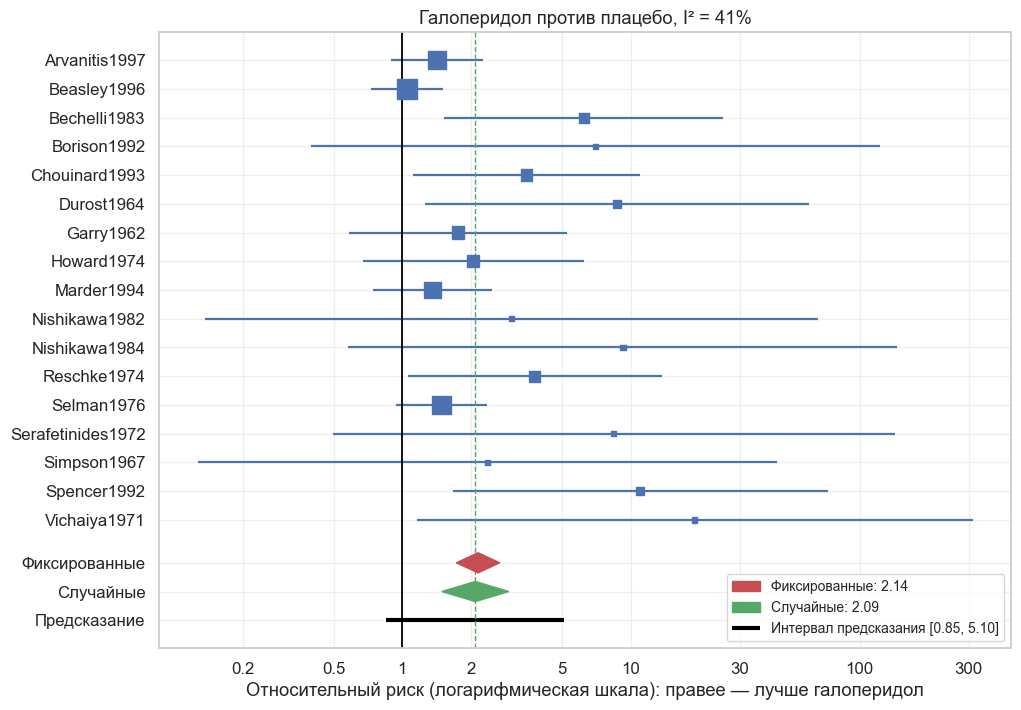

In [14]:
weights_re = 1 / (variance + tau2)
share = 100 * weights_re / weights_re.sum()
se_study = np.sqrt(variance)
order = np.arange(k)[::-1] + 3

fig, ax = plt.subplots(figsize=(11, 8))
ax.hlines(order, np.exp(log_rr - 1.96 * se_study), np.exp(log_rr + 1.96 * se_study), color=BLUE, lw=1.6)
ax.scatter(np.exp(log_rr), order, s=share * 12, marker='s', color=BLUE, zorder=3)


def diamond(row, centre, low, high, color, label):
    ax.fill([low, centre, high, centre], [row, row + 0.35, row, row - 0.35], color=color, label=label, zorder=3)


diamond(1.5, rr_mh, np.exp(np.log(rr_mh) - 1.96 * se_mh), np.exp(np.log(rr_mh) + 1.96 * se_mh), RED, f'Фиксированные: {rr_mh:.2f}')
diamond(0.5, np.exp(mean_re), np.exp(mean_re - 1.96 * se_re), np.exp(mean_re + 1.96 * se_re), GREEN, f'Случайные: {np.exp(mean_re):.2f}')
ax.hlines(-0.5, prediction[0], prediction[1], color='black', lw=3, label=f'Интервал предсказания [{prediction[0]:.2f}, {prediction[1]:.2f}]')
ax.axvline(1, color='black', lw=1.3)
ax.axvline(np.exp(mean_re), color=GREEN, ls='--', lw=1)
ax.set_xscale('log')
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 30, 100, 300], ['0.2', '0.5', '1', '2', '5', '10', '30', '100', '300'])
ax.set_yticks(list(order) + [1.5, 0.5, -0.5], list(data['authoryear']) + ['Фиксированные', 'Случайные', 'Предсказание'])
ax.set_xlabel('Относительный риск (логарифмическая шкала): правее — лучше галоперидол')
ax.set_title(f'Галоперидол против плацебо, I² = {i2:.0%}')
ax.legend(loc='lower right', fontsize=10);

Оба ромба лежат справа от линии отсутствия эффекта: фиксированные эффекты дают RR 2.14, случайные 2.09, и галоперидол значимо лучше плацебо. Интервал случайных эффектов шире, а с поправкой Хартунга — Кнаппа это [1.43, 3.04].

Интервал предсказания [0.85, 5.10] пересекает единицу. Значит, в отдельном новом исследовании эффекта может и не быть. $Q$-тест значим ($p = 0.038$), $I^2$ равен 41%, то есть гетерогенность умеренная.

Обратите внимание на три самых крупных исследования: Arvanitis, Beasley и Marder дают RR от 1.05 до 1.42, и ни одно из них не значимо. Большие RR идут от малых исследований.

### Эффект малых исследований

**Эффект малых исследований** возникает, когда малые исследования показывают другой, часто больший эффект. Причиной может быть публикационное смещение, а может и более низкое качество малых исследований или другая популяция.

Проверим его тремя способами.

* **Воронкообразный график:** оцениваем симметрию.
* **Контурная воронка:** добавляем области значимости. Если пропуски приходятся на незначимую зону, это аргумент в пользу публикационного смещения.
* **Тест Эггера:** регрессия стандартизированного эффекта $y_i / SE_i$ на точность $1/SE_i$. Значимый свободный член указывает на асимметрию.

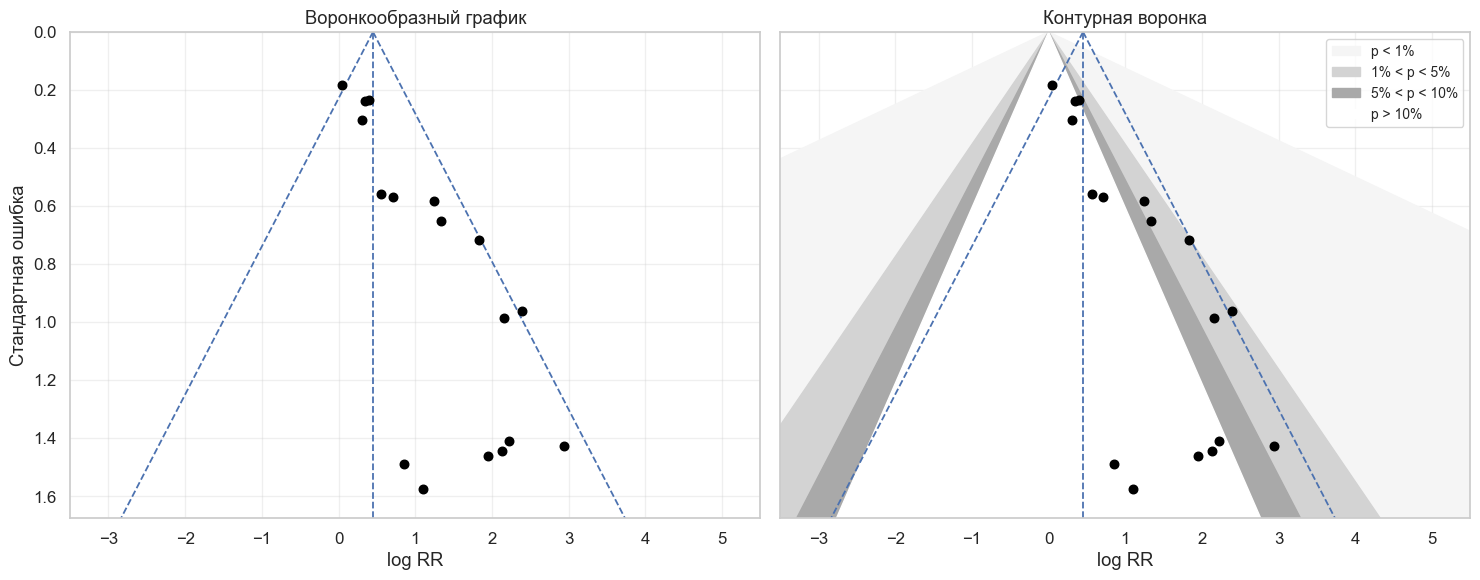

Тест Эггера: свободный член 1.79, p-value 4.7e-06


In [15]:
se_max = se_study.max() + 0.1
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for z_level, color, label in [(np.inf, 'whitesmoke', 'p < 1%'), (2.58, 'lightgray', '1% < p < 5%'), (1.96, 'darkgrey', '5% < p < 10%'), (1.65, 'white', 'p > 10%')]:
    level = min(z_level, 8)
    axes[1].fill([-level * se_max, 0, level * se_max], [se_max, 0, se_max], color=color, label=label)

for ax in axes:
    ax.plot([mean_fe, mean_fe - 1.96 * se_max], [0, se_max], color=BLUE, ls='--', lw=1.3)
    ax.plot([mean_fe, mean_fe + 1.96 * se_max], [0, se_max], color=BLUE, ls='--', lw=1.3)
    ax.axvline(mean_fe, color=BLUE, ls='--', lw=1.3)
    ax.scatter(log_rr, se_study, color='black', s=38, zorder=3)
    ax.set_xlabel('log RR')
    ax.set_xlim(-3.5, 5.5)
axes[0].set_ylim(se_max, 0)
axes[0].set_ylabel('Стандартная ошибка')
axes[0].set_title('Воронкообразный график')
axes[1].set_title('Контурная воронка')
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

egger = sm.OLS(log_rr / se_study, sm.add_constant(1 / se_study)).fit()
print(f'Тест Эггера: свободный член {egger.params[0]:.2f}, p-value {egger.pvalues[0]:.2g}')

Воронка заметно асимметрична: малые исследования сдвинуты вправо, а слева от центра малых исследований нет. Многие точки лежат у границы значимости. Тест Эггера подтверждает это: свободный член 1.79, $p < 0.001$.

Это повод для осторожности, но не доказательство публикационного смещения. Для бинарных исходов стандартная ошибка логарифма RR сама зависит от числа событий, поэтому тест Эггера склонен к ложным срабатываниям. Поэтому для таких данных есть тесты Питерса и Харборда. Малые старые испытания могут ещё и отличаться по качеству и популяции. В любом случае общая оценка 2.09, вероятно, завышена: крупные исследования указывают на меньший эффект.

## Заключение

| Задача | Метод | Что важно помнить |
| :--- | :--- | :--- |
| Оценить средний эффект | Случайные эффекты с HK | При малом $k$ оценка $\tau^2$ неточна |
| Понять, откуда разброс | Мета-регрессия | Наблюдательный анализ, масштаб фиксирован |
| Объединить независимые p-value | Фишер или Стоуффер | Стоуффер сохраняет направление, Фишер нет |
| Объединить зависимые тесты | HMP, Бонферрони | Фишер неприменим, HMP без гарантий при сильной зависимости |
| Редкие события | Мантель — Хензель или Пето | Пето только при равных группах и небольшом эффекте |

Главное из лекции:

* мета-анализ не исправляет плохой дизайн и отбор тестов: мусор на входе даёт мусор на выходе;
* модель фиксированных эффектов при гетерогенности даёт слишком узкие интервалы;
* отклонение общей $H_0$ означает эффект хотя бы в одном тесте, а не во всех;
* интервал предсказания показывает, чего ждать от нового теста, и часто он намного шире доверительного;
* база успешных тестов смещена, поэтому для честного мета-анализа нужно хранить все тесты.